In [1]:
import os
import sys
import torch
import torch.optim as optim
import torch.nn.functional as F
import tqdm
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from scipy.optimize import minimize
import plotly.graph_objects as go
from matplotlib.colors import LogNorm
from skimage.transform import resize
#%matplotlib widget
from pathlib import Path


workspace_path = os.path.dirname(os.path.dirname(os.path.abspath("__file__")))
sys.path.append(workspace_path)

from lib.utils_sim import *
from lib.propagation import *

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
sim_params = {
    'sim_width'  : 128,
    'sim_height' : 128,
    'obj_name' : 'bunny-halfcut',
    'obj_zdist': 100,
    'theta_s': 20,
    'phi_s'  :  40,
    'candidates' : 50,
    }
width  = sim_params['sim_width']
height = sim_params['sim_height']

In [3]:
if sim_params['obj_name'] is not None:
    camera_mesh_name = f"{sim_params['obj_name']}_camera_{width}x{height}_{sim_params['obj_zdist']}"
    camera_mesh_path = Path(workspace_path) / f"objs/{camera_mesh_name}.obj"
    
    if not camera_mesh_path.exists():
        construct_camera_mesh(sim_params['obj_name'], width, height, sim_params['obj_zdist'])
    
    # Load camera mesh
    verts_np, faces_np = get_vf_for_obj(camera_mesh_name, norm=False)
    
else:
    # define triangular mesh with simple geometry
    verts_np, faces_np, ii, jj = create_reg_tri_mesh_from_camera(width, height)
    verts_np[:, 2] = -(verts_np[:, 0]**2 + verts_np[:, 1]**2)
    mask = np.zeros(verts_np.shape[0])

pixel_pitch = verts_np[1, 0] - verts_np[0, 0]

# create Trimesh object
mesh = trimesh.Trimesh(vertices=verts_np, faces=faces_np)

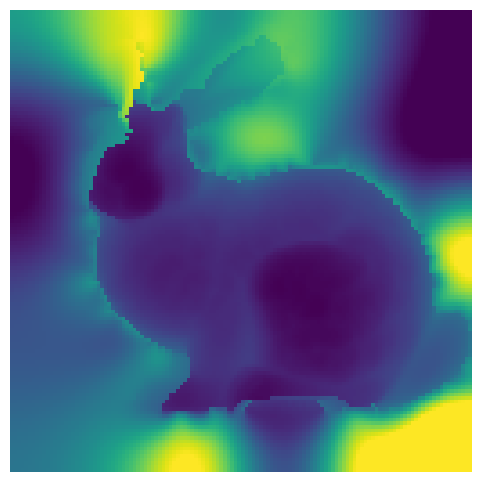

In [4]:
# depth
depth_values = -verts_np[:, 2]
depth_map_gt = depth_values.reshape((height, width))
depth_min = depth_map_gt.min()
depth_max = depth_map_gt.max()
depth_map_gt_normalized = (depth_map_gt - depth_min) / (depth_max - depth_min)

plt.figure(figsize=(6, 6))
plt.imshow(depth_map_gt_normalized, origin='lower')
plt.axis('off')
plt.show()

In [7]:
path1 = os.path.join(workspace_path, "results/optimized-res/result-20251217_122234-bunny.obj")
mesh1 = trimesh.load(path1, process=False)
verts1 = mesh1.vertices

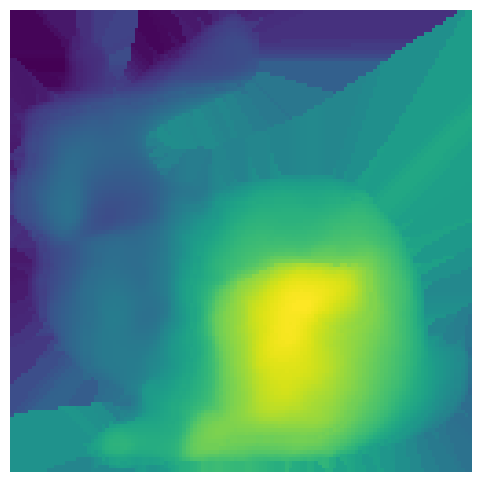

OK: resampled depth map displayed.
depth range: -0.018430247902870178 0.012851670384407043


In [10]:
import numpy as np
import trimesh
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree  # これが使える前提（scipy）

def depth_map_from_obj_resample_nn(obj_path, height, width, z_sign=+1):
    """
    OBJの頂点群 (x,y,z) を height×width の規則グリッドに最近傍で再サンプルし、depth map を作る。
    z_sign: depth = z_sign * z で符号を合わせる（必要なら -1 に）
    """
    mesh = trimesh.load(obj_path, process=False)
    verts = np.asarray(mesh.vertices, dtype=np.float64)

    x = verts[:, 0]
    y = verts[:, 1]
    z = z_sign * verts[:, 2]

    # ターゲットグリッド（OBJのXY範囲に合わせる）
    xs = np.linspace(x.min(), x.max(), width)
    ys = np.linspace(y.min(), y.max(), height)
    Xg, Yg = np.meshgrid(xs, ys)  # shape (H,W)

    # 最近傍探索
    pts = np.stack([x, y], axis=1)
    tree = cKDTree(pts)
    qpts = np.stack([Xg.ravel(), Yg.ravel()], axis=1)
    _, idx = tree.query(qpts, k=1)

    Zg = z[idx].reshape(height, width)
    return Zg

def normalize01(a, eps=1e-12):
    a = np.asarray(a, float)
    mn, mx = np.nanmin(a), np.nanmax(a)
    return (a - mn) / (mx - mn + eps)


path1 = os.path.join(workspace_path, "results/optimized-res/result-20251217_122234-bunny.obj")

height, width = 126, 126

# depth = z のままで良いなら z_sign=+1、GTと合わせて depth=-z なら z_sign=-1
depth_map_1 = depth_map_from_obj_resample_nn(path1, height, width, z_sign=+1)

depth_map_1_normalized = normalize01(depth_map_1)

plt.figure(figsize=(6, 6))
plt.imshow(depth_map_1_normalized, origin="lower")
plt.axis("off")
plt.show()

print("OK: resampled depth map displayed.")
print("depth range:", float(depth_map_1.min()), float(depth_map_1.max()))


In [11]:
# verts = verts1.copy()

# height, width = 126, 126
# depth_values  = verts[:, 2]
# depth_map_1   = depth_values.reshape((height, width))
# depth_min = depth_map_1.min()
# depth_max = depth_map_1.max()
# depth_map_1_normalized = (depth_map_1 - depth_min) / (depth_max - depth_min)

# plt.figure(figsize=(6, 6))
# plt.imshow(depth_map_1_normalized, origin='lower')
# plt.axis('off')
# plt.show()

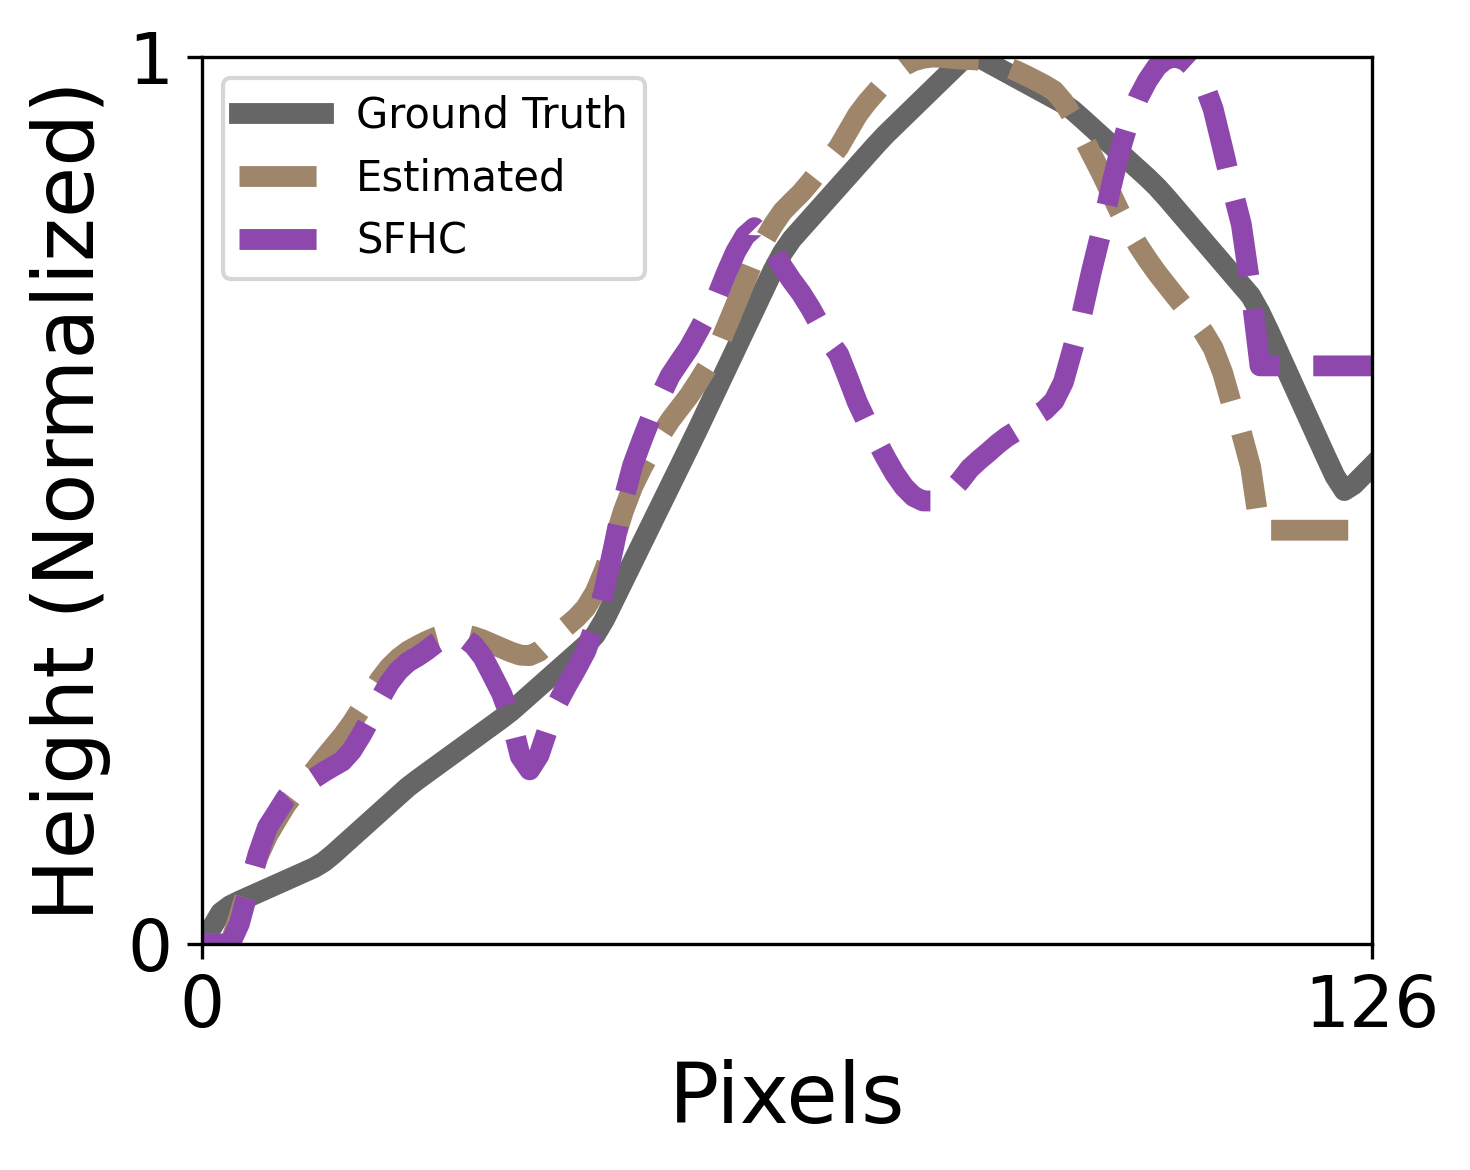

In [14]:
import matplotlib.pyplot as plt
import trimesh

def normalize01(a, eps=1e-12):
    a = np.asarray(a, float)
    mn, mx = np.nanmin(a), np.nanmax(a)
    return (a - mn) / (mx - mn + eps)

def load_mesh(obj_path):
    return trimesh.load(obj_path, process=False)

def common_y_center(meshes):
    y_mins = [m.vertices[:, 1].min() for m in meshes]
    y_maxs = [m.vertices[:, 1].max() for m in meshes]
    y_min = max(y_mins); y_max = min(y_maxs)
    if not (y_min < y_max):
        raise RuntimeError("3つのOBJでy範囲が重なっていません（座標系が違う可能性）")
    return 0.5 * (y_min + y_max)

def line_profile_raycast(mesh, y0, n_samples=512, z_sign=-1, z_pad=10.0):
    """
    y=y0 上の多数点から -z 方向にレイを飛ばし、最初の交点の z を取る。
    頂点最近傍より“面上”の断面になるので滑らかになる。
    """
    v = mesh.vertices
    x_min, x_max = v[:, 0].min(), v[:, 0].max()
    xs = np.linspace(x_min, x_max, n_samples)

    # ray origin: 충분に上（+z）から落とす
    z_top = v[:, 2].max() + z_pad
    origins = np.stack([xs, np.full_like(xs, y0), np.full_like(xs, z_top)], axis=1)
    directions = np.tile(np.array([0.0, 0.0, -1.0]), (n_samples, 1))

    # ray intersection (first hit)
    locations, ray_id, _ = mesh.ray.intersects_location(
        ray_origins=origins,
        ray_directions=directions,
        multiple_hits=False
    )

    # 結果配列（当たらない所はNaN）
    z_hit = np.full(n_samples, np.nan, dtype=np.float64)
    if len(ray_id) > 0:
        z_hit[ray_id] = locations[:, 2]

    # depth sign
    z_hit = z_sign * z_hit
    return xs, z_hit

def interp_to_common_x(xs, ys, x_common):
    # NaN を除いた上で補間
    m = np.isfinite(ys)
    if m.sum() < 2:
        return np.full_like(x_common, np.nan, dtype=float)
    return np.interp(x_common, xs[m], ys[m])

def shift_min_to_zero(line):
    line = np.asarray(line, float)
    m = np.isfinite(line)
    if not np.any(m):
        return line
    return line - np.nanmin(line)

# -----------------------------
# Main
# -----------------------------
z_sign = 1
n_samples_ray = 2048   # ←GTの解像度はここで上げる（512, 1024, 2048…）
n_samples_plot = 126   # 表示は 0..126 の “ピクセル数” に合わせる

path_gt = os.path.join(workspace_path, "results/optimized-res/bunny-halfcut_camera_128x128_100.obj")
path_est = os.path.join(workspace_path, "results/optimized-res/result-20251217_122234-bunny.obj")
path_sfhc = os.path.join(workspace_path, "results/optimized-res/result-20251219_135336-bunny-baseline.obj")

m_gt = load_mesh(path_gt)
m_est = load_mesh(path_est)
m_sfhc = load_mesh(path_sfhc)

delta = 0.009
y0 = common_y_center([m_gt, m_est, m_sfhc]) - delta

# raycast profiles (面上で取れるので滑らか)
x_gt, z_gt = line_profile_raycast(m_gt, y0, n_samples=n_samples_ray, z_sign=z_sign)
x_est, z_est = line_profile_raycast(m_est, y0, n_samples=n_samples_ray, z_sign=z_sign)
x_sfhc, z_sfhc = line_profile_raycast(m_sfhc, y0, n_samples=n_samples_ray, z_sign=z_sign)

# 共通x範囲
x_min = max(np.nanmin(x_gt), np.nanmin(x_est), np.nanmin(x_sfhc))
x_max = min(np.nanmax(x_gt), np.nanmax(x_est), np.nanmax(x_sfhc))
x_common = np.linspace(x_min, x_max, n_samples_plot)

gt_line = interp_to_common_x(x_gt, z_gt, x_common)
est_line = interp_to_common_x(x_est, z_est, x_common)
sfhc_line = interp_to_common_x(x_sfhc, z_sfhc, x_common)

# 0-1正規化
gt_n = normalize01(gt_line)
est_n = normalize01(est_line)
sfhc_n = normalize01(sfhc_line)

# 見た目調整（必要なら）
est_n = np.clip(shift_min_to_zero(est_n), 0, 1)
sfhc_n = np.clip(shift_min_to_zero(sfhc_n), 0, 1)

# plot axis 0..126
x_pix = np.linspace(0, 126, n_samples_plot)

plt.figure(figsize=(5, 4), dpi=300)
plt.plot(x_pix, gt_n, color=(0,0,0,0.6), linewidth=5, label="Ground Truth")
plt.plot(x_pix, est_n, color="#9F866A", linestyle="--", linewidth=5, label="Estimated")
plt.plot(x_pix, sfhc_n, color="#8E48AD", linestyle="--", linewidth=5, label="SFHC")
plt.xlabel("Pixels", fontsize=20)
plt.ylabel("Height (Normalized)", fontsize=20)
plt.xlim(0, 126); plt.xticks([0, 126], fontsize=17)
plt.ylim(0, 1);   plt.yticks([0, 1], fontsize=17)
plt.legend(fontsize=10, frameon=True, loc="upper left")
plt.tight_layout()
plt.show()

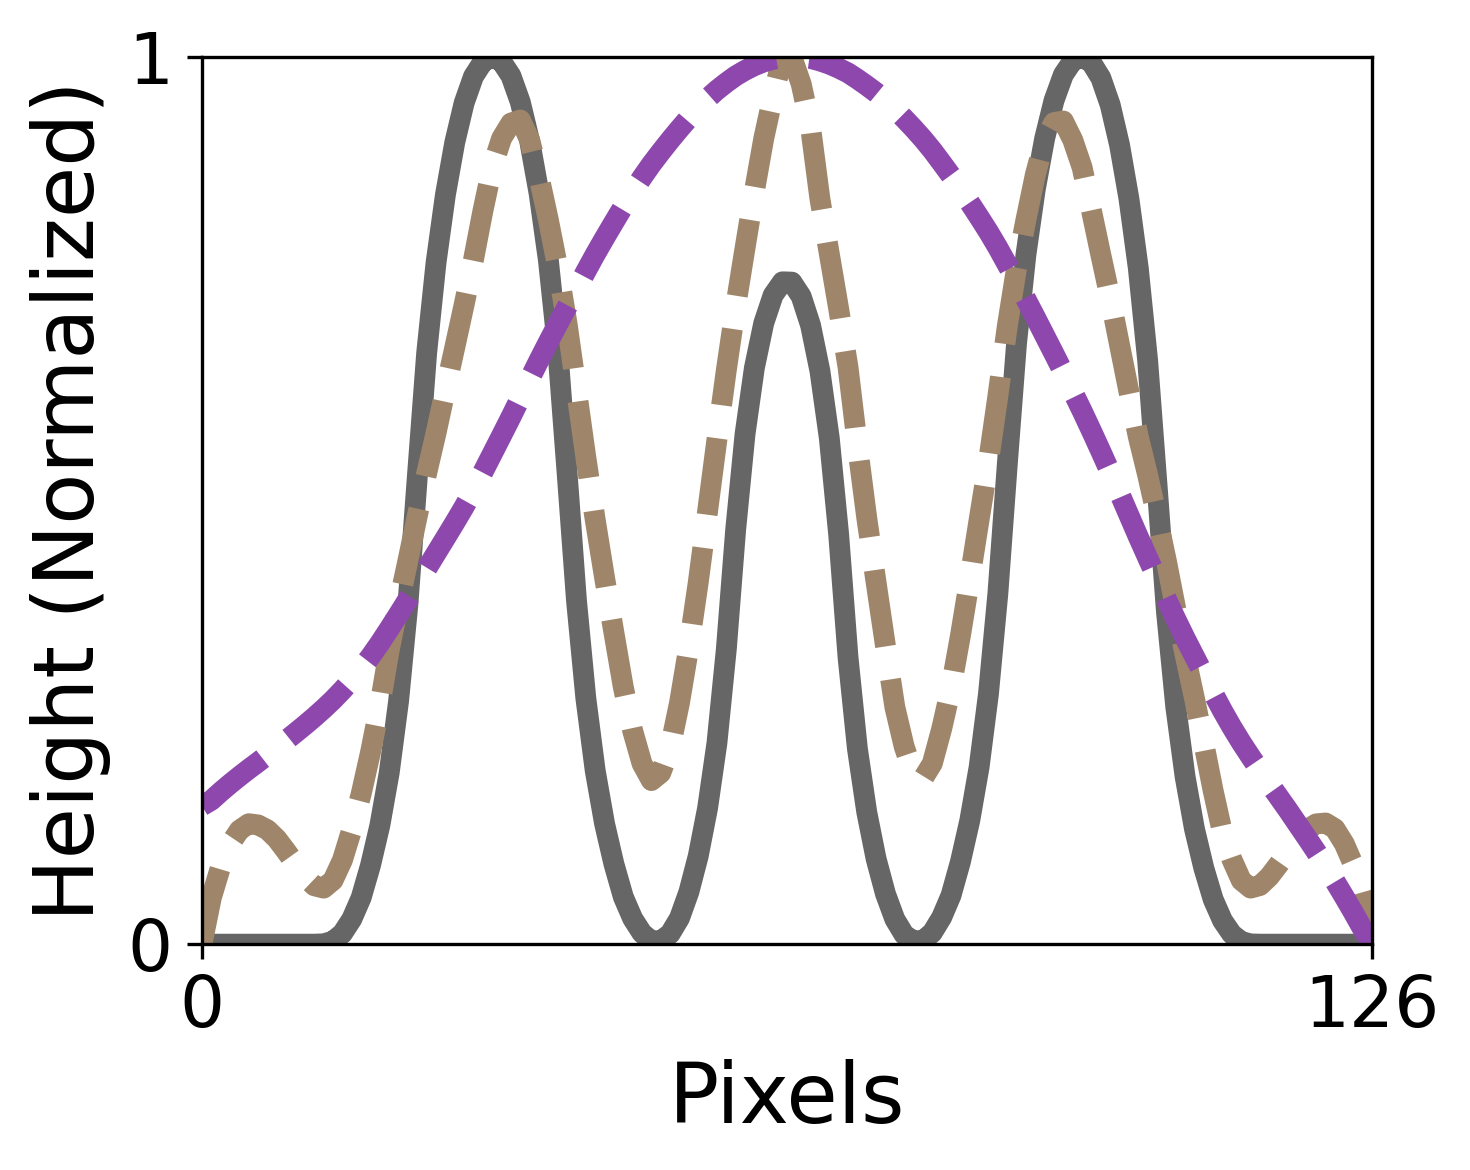

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import trimesh

def normalize01(a, eps=1e-12):
    a = np.asarray(a, float)
    mn, mx = np.nanmin(a), np.nanmax(a)
    return (a - mn) / (mx - mn + eps)

def load_mesh(obj_path):
    return trimesh.load(obj_path, process=False)

def common_y_center(meshes):
    y_mins = [m.vertices[:, 1].min() for m in meshes]
    y_maxs = [m.vertices[:, 1].max() for m in meshes]
    y_min = max(y_mins); y_max = min(y_maxs)
    if not (y_min < y_max):
        raise RuntimeError("3つのOBJでy範囲が重なっていません（座標系が違う可能性）")
    return 0.5 * (y_min + y_max)

def line_profile_raycast(mesh, y0, n_samples=512, z_sign=-1, z_pad=10.0):
    v = mesh.vertices
    x_min, x_max = v[:, 0].min(), v[:, 0].max()
    xs = np.linspace(x_min, x_max, n_samples)

    z_top = v[:, 2].max() + z_pad
    origins = np.stack([xs, np.full_like(xs, y0), np.full_like(xs, z_top)], axis=1)
    directions = np.tile(np.array([0.0, 0.0, -1.0]), (n_samples, 1))

    locations, ray_id, _ = mesh.ray.intersects_location(
        ray_origins=origins,
        ray_directions=directions,
        multiple_hits=False
    )

    z_hit = np.full(n_samples, np.nan, dtype=np.float64)
    if len(ray_id) > 0:
        z_hit[ray_id] = locations[:, 2]

    z_hit = z_sign * z_hit
    return xs, z_hit

def interp_to_common_x(xs, ys, x_common):
    m = np.isfinite(ys)
    if m.sum() < 2:
        return np.full_like(x_common, np.nan, dtype=float)
    return np.interp(x_common, xs[m], ys[m])

def shift_min_to_zero(line):
    line = np.asarray(line, float)
    m = np.isfinite(line)
    if not np.any(m):
        return line
    return line - np.nanmin(line)

# -----------------------------
# Main
# -----------------------------
z_sign = 1
n_samples_ray = 2048
n_samples_plot = 126

path_gt = os.path.join(workspace_path, "results/optimized-res/concave_wave_camera_128x128_100.obj")
path_est = os.path.join(workspace_path, "results/optimized-res/result-20251229_213016-droplet.obj")
path_sfhc = os.path.join(workspace_path, "results/optimized-res/result-20251229_224216-droplet-baseline.obj")


m_gt = load_mesh(path_gt)
m_est = load_mesh(path_est)
m_sfhc = load_mesh(path_sfhc)

y0 = common_y_center([m_gt, m_est, m_sfhc])

# raycast
x_gt, z_gt = line_profile_raycast(m_gt, y0, n_samples=n_samples_ray, z_sign=-z_sign)
x_est, z_est = line_profile_raycast(m_est, y0, n_samples=n_samples_ray, z_sign=z_sign)
x_sfhc, z_sfhc = line_profile_raycast(m_sfhc, y0, n_samples=n_samples_ray, z_sign=z_sign)

# -----------------------------------------
# EST / SFHC は絶対に変更しない：共通範囲
# -----------------------------------------
x_min = max(np.nanmin(x_gt), np.nanmin(x_est), np.nanmin(x_sfhc))
x_max = min(np.nanmax(x_gt), np.nanmax(x_est), np.nanmax(x_sfhc))
x_common = np.linspace(x_min, x_max, n_samples_plot)

est_line  = interp_to_common_x(x_est,  z_est,  x_common)
sfhc_line = interp_to_common_x(x_sfhc, z_sfhc, x_common)

# -----------------------------------------
# ★GTだけ修正：GT自身の範囲で 0-126 を作る
# -----------------------------------------
x_common_gt = np.linspace(np.nanmin(x_gt), np.nanmax(x_gt), n_samples_plot)
gt_line = interp_to_common_x(x_gt, z_gt, x_common_gt)

# 0-1正規化（今まで通り）
gt_n   = normalize01(gt_line)
est_n  = normalize01(est_line)
sfhc_n = normalize01(sfhc_line)

# 見た目調整（今まで通り：EST/SFHCだけ）
est_n  = np.clip(shift_min_to_zero(est_n), 0, 1)
sfhc_n = np.clip(shift_min_to_zero(sfhc_n), 0, 1)

# plot axis 0..126
x_pix = np.linspace(0, 126, n_samples_plot)

plt.figure(figsize=(5, 4), dpi=300)
plt.plot(x_pix, gt_n,   color=(0,0,0,0.6), linewidth=5, label="Ground Truth")
plt.plot(x_pix, est_n,  color="#9F866A", linestyle="--", linewidth=5, label="Estimated")
plt.plot(x_pix, sfhc_n, color="#8E48AD", linestyle="--", linewidth=5, label="SFHC")

plt.xlabel("Pixels", fontsize=20)
plt.ylabel("Height (Normalized)", fontsize=20)
plt.xlim(0, 126); plt.xticks([0, 126], fontsize=17)
plt.ylim(0, 1);   plt.yticks([0, 1], fontsize=17)
# plt.legend(fontsize=10, frameon=True, loc="upper right")
plt.tight_layout()
plt.show()
